In [45]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

import geopandas as gpd
import contextily as ctx


In [6]:
# Paths to folders

parent_dir = Path(r"/home/jovyan/shared/common/norsink/vm_catchments_data/gridded_by_site")

# raw_dir = os.path.join(parent_dir, "raw")
raw_dir = parent_dir / "raw"  # instead of os.path.join, this works if have imported Path
daily_out_dir = parent_dir / "processed" / "daily"
annual_out_dir = parent_dir / "processed" / "annual"
static_out_dir = parent_dir / "processed" / "static"

annual_fpath = annual_out_dir / "gts_q-met_annual.csv"
summary_fpath = static_out_dir / "gts_q-met_annual_mean.csv"

In [4]:
annual_df = pd.read_csv(annual_fpath)
annual_df

,year,runoff_annual,precip_annual,temp_annual,site_code
0,1980,303.89,868.21,3.23,001-119928
1,1981,322.40,895.06,3.17,001-119928
2,1982,367.49,912.92,4.54,001-119928
3,1983,288.91,737.78,5.19,001-119928
4,1984,275.10,846.69,4.85,001-119928
...,...,...,...,...,...
390167,2021,441.45,531.90,4.67,314-89994
390168,2022,228.75,885.70,5.42,314-89994
390169,2023,618.15,903.50,4.61,314-89994
390170,2024,596.55,941.45,5.43,314-89994


In [25]:
static_df = pd.read_csv(summary_fpath)
static_df["runoff_coeff"] = static_df["runoff_mean_annual"] / static_df["precip_mean_annual"]
static_df

,site_code,gts_runoff_q95,has_runoff,has_precip,has_temp,runoff_mean_annual,precip_mean_annual,temp_mean_annual,runoff_coeff
0,001-119928,3.182,True,True,True,371.069,894.139,4.914,0.415001
1,001-119929,3.194,True,True,True,370.057,895.039,4.921,0.413453
2,001-30653,4.350,True,True,True,468.331,1007.832,6.547,0.464692
3,001-30683,4.122,True,True,True,457.043,897.038,6.820,0.509502
4,001-30687,4.529,True,True,True,501.268,1071.671,5.979,0.467744
...,...,...,...,...,...,...,...,...,...
8477,313-99151,2.341,True,True,True,272.217,861.527,4.465,0.315970
8478,314-46646,4.225,True,True,True,472.868,933.190,4.647,0.506722
8479,314-48074,3.831,True,True,True,441.019,924.632,4.397,0.476967
8480,314-62046,NaN,False,True,True,NaN,977.549,4.969,NaN


In [9]:
pt_dir = Path(r"/home/jovyan/shared/common/norsink/spatial/monitored_chem_catchments")
pts_fpath = pt_dir / "outlet_locations_vm-rivs-quant-oc_v3-full.csv"
pts_df = pd.read_csv(pts_fpath)

# (N.B. only column 'frac_outside_no' to be used for filtering, the others are useful but contain NaNs)
pts_df = pts_df.rename(
    {
        "frac_sw": "fraction_sweden",
        "frac_ru": "fraction_russia",
        "frac_fi": "fraction_finland",
    },
    axis=1,
)

print("Number of sites to start with:", len(pts_df))

# Useful metadata (or potentially features)
print("Number of points in lakes:", (pts_df['pt_in_lake'] == True).sum())
                                        
# Probably drop sites where > 50% of the delimited catchment is outside Norway?
# Though maybe do this based on vassdragsområdenummer as well/instead?
crossborder_catchs = pts_df.loc[pts_df['frac_outside_no'] > 0.5]
print("Number of crossborder catchs (>50% outside NO):", len(crossborder_catchs))
display(crossborder_catchs)

# List of catchchment ids to add to "drop" list
drop_crossborder_catchs = list(crossborder_catchs['site_code'])

Number of sites to start with: 8482
Number of points in lakes: 173
Number of crossborder catchs (>50% outside NO): 17


,site_code,lon,lat,site_id,Name,start_year,end_year,n_years,n_samples,av_freq,pt_in_lake,area_km2,fraction_sweden,fraction_finland,fraction_russia,frac_outside_no
7,001-30735,11.537422,58.877626,30735,ENI4 ENNINGDALSELVA,1991,1991,1.0,5,5.00,False,124.153424,0.968068,0.000000,0.00000,0.968068
8,001-30745,11.490473,58.960694,30745,Enningdalselva (ENI 2),1991,2010,18.7,30,1.60,False,212.224869,0.580317,0.000000,0.00000,0.580317
9,001-31059,11.520638,58.910288,31059,ENI3 ENNINGDALSELVA,1991,1991,1.0,5,5.00,False,191.358069,0.643600,0.000000,0.00000,0.643600
30,001-61955,11.687507,59.479914,61955,Braneselva,2012,2012,1.0,2,2.00,False,10.159504,0.556863,0.000000,0.00000,0.556863
31,001-62044,11.711326,59.485813,62044,Braneselva v/Foss,2012,2012,1.0,2,2.00,False,6.444111,0.862605,0.000000,0.00000,0.862605
32,001-62045,11.684948,59.477881,62045,"Braneselva nedstrøms E18, 16_08",2012,2012,1.0,2,2.00,False,10.317495,0.548336,0.000000,0.00000,0.548336
6955,124-104986,12.036398,63.335585,104986,Steinfjellgrenda,2021,2022,1.0,2,2.00,False,16.228020,0.856263,0.000000,0.00000,0.856263
6956,124-104987,12.031988,63.340020,104987,Mellomveien,2021,2021,1.0,1,1.00,False,18.977961,0.828958,0.000000,0.00000,0.828958
8309,234-63085,28.050541,70.050751,63085,Polmakelva (Buolbmátjohka) ovenfor avfallsfylling,2013,2013,1.0,3,3.00,False,772.488600,0.000000,0.804516,0.00000,0.804516
8342,234-M4,27.000550,69.782890,-4,Utsjoki (Patoniva),2023,2023,1.0,154,154.00,False,1373.865638,0.000000,1.000000,0.00000,1.000000


In [30]:
join_df = pd.merge(pts_df, static_df, on="site_code", how="inner", validate="one_to_one")
join_df

,site_code,lon,lat,site_id,Name,start_year,end_year,n_years,n_samples,av_freq,...,fraction_russia,frac_outside_no,gts_runoff_q95,has_runoff,has_precip,has_temp,runoff_mean_annual,precip_mean_annual,temp_mean_annual,runoff_coeff
0,001-119928,11.653745,59.476520,119928,Oppstrøms Bommen RA,2011,2025,14.0,14,1.00,...,0.0,0.010104,3.182,True,True,True,371.069,894.139,4.914,0.415001
1,001-119929,11.654461,59.472300,119929,Nedstrøms Bommen RA,2011,2025,14.0,14,1.00,...,0.0,0.010099,3.194,True,True,True,370.057,895.039,4.921,0.413453
2,001-30653,11.437438,59.070299,30653,YSTE YSTEHEDEBEKKEN,1987,1987,1.0,4,4.00,...,0.0,0.000000,4.350,True,True,True,468.331,1007.832,6.547,0.464692
3,001-30683,11.295421,59.121185,30683,"Unnebergbekken, UNNE",1987,2016,29.1,5,0.17,...,0.0,0.000000,4.122,True,True,True,457.043,897.038,6.820,0.509502
4,001-30687,11.528412,58.987892,30687,ØRB2 ØRBEKKEN,1991,1991,1.0,4,4.00,...,0.0,0.000000,4.529,True,True,True,501.268,1071.671,5.979,0.467744
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8477,313-99151,12.111818,59.990523,99151,Hesbølsjøen utløp,2024,2024,1.0,5,5.00,...,0.0,0.000000,2.341,True,True,True,272.217,861.527,4.465,0.315970
8478,314-46646,11.699073,59.634394,46646,"Åkevannet, utløp",2011,2022,11.0,4,0.36,...,0.0,0.000000,4.225,True,True,True,472.868,933.190,4.647,0.506722
8479,314-48074,11.924796,59.747409,48074,"Røvatnet, utløp",2011,2011,1.0,1,1.00,...,0.0,0.738743,3.831,True,True,True,441.019,924.632,4.397,0.476967
8480,314-62046,11.730778,59.479630,62046,Håbyelva,2012,2012,1.0,2,2.00,...,0.0,1.000000,NaN,False,True,True,NaN,977.549,4.969,NaN


In [36]:
meta_cols = [
    "lon",
    "lat",
    "site_code",
    "Name",
    "n_samples",
    "pt_in_lake",
    "area_km2",
    "frac_outside_no",
    "gts_runoff_q95",
    "has_runoff",
    "has_precip",
    "runoff_mean_annual",
    "precip_mean_annual",
    "temp_mean_annual",
    'runoff_coeff',
]

In [37]:
join_df[meta_cols].describe()

,lon,lat,n_samples,area_km2,frac_outside_no,gts_runoff_q95,runoff_mean_annual,precip_mean_annual,temp_mean_annual,runoff_coeff
count,8482.000000,8482.000000,8482.000000,8482.000000,8482.000000,8478.000000,8478.000000,8481.000000,8481.000000,8477.000000
mean,9.913985,61.265743,19.646899,371.046094,0.003567,11.957765,1301.027543,1438.768158,3.726500,0.822870
std,3.602953,2.740834,81.779150,2071.385570,0.040312,8.409749,1091.795300,696.502301,2.486591,0.378737
min,4.693305,58.018357,1.000000,0.314898,0.000000,1.100000,108.226000,432.127000,-4.772000,0.185443
25%,7.706517,59.579832,2.000000,2.223637,0.000000,5.690500,549.676000,962.242000,1.961000,0.531808
50%,9.952011,60.361049,4.500000,8.748207,0.000000,9.438000,870.553500,1161.935000,4.281000,0.725954
75%,10.999183,61.942946,12.000000,51.573524,0.000000,15.975000,1665.692250,1751.226000,5.655000,1.030703
max,30.952229,70.962425,2020.000000,41698.280949,1.000000,49.600000,6686.449000,4387.908000,8.081000,3.107736


In [38]:
join_df.loc[join_df["runoff_mean_annual"] < 200, meta_cols].describe()

,lon,lat,n_samples,area_km2,frac_outside_no,gts_runoff_q95,runoff_mean_annual,precip_mean_annual,temp_mean_annual,runoff_coeff
count,43.000000,43.000000,43.000000,43.000000,43.0,43.000000,43.000000,43.000000,43.000000,43.000000
mean,16.291991,64.063499,11.139535,9.987124,0.0,1.612674,174.042698,598.935279,2.950930,0.299563
std,6.961350,4.535058,24.603118,13.830143,0.0,0.177783,18.896666,110.527394,2.287732,0.059482
min,9.080587,60.095817,1.000000,0.644231,0.0,1.100000,108.226000,440.224000,-1.856000,0.185443
25%,11.228813,60.667384,2.500000,1.232798,0.0,1.535500,162.944000,483.124500,0.700000,0.260677
50%,11.507675,60.798458,3.000000,2.912473,0.0,1.584000,179.689000,644.153000,3.942000,0.289774
75%,25.015408,69.899012,9.000000,14.014625,0.0,1.700000,186.659000,682.759500,4.533000,0.341516
max,30.006280,70.099877,156.000000,46.188465,0.0,2.100000,198.873000,809.817000,5.931000,0.439392


In [39]:
low_runoff_df = join_df.loc[join_df["runoff_mean_annual"] < 200, meta_cols]
low_runoff_df

,lon,lat,site_code,Name,n_samples,pt_in_lake,area_km2,frac_outside_no,gts_runoff_q95,has_runoff,has_precip,runoff_mean_annual,precip_mean_annual,temp_mean_annual,runoff_coeff
154,11.141844,60.666090,002-108253,Hvitbergåa,12,False,7.930173,0.0,1.529,True,True,180.234,675.930,4.613,0.266646
156,11.183304,60.686851,002-108487,Osvollåa v. Hagastua,6,False,2.603710,0.0,1.600,True,True,181.191,686.534,4.356,0.263921
218,11.138614,60.798458,002-114449,Ridabu,1,False,1.178478,0.0,1.600,True,True,198.100,610.848,4.530,0.324303
245,11.609835,60.819581,002-118349,"Bergebekken, utløp Glomma",2,False,5.460941,0.0,1.567,True,True,178.639,696.591,3.942,0.256447
246,11.598166,60.818499,002-118350,Tilløp Bergebekken,3,False,4.448178,0.0,1.540,True,True,171.753,696.627,3.881,0.246549
248,11.741813,60.761617,002-118478,Nedstrøms Rokmyra,2,False,2.912473,0.0,1.375,True,True,159.140,735.757,4.234,0.216294
287,11.247890,60.594009,002-118869,Utløp trosvika,6,False,0.974569,0.0,1.300,True,True,138.852,748.759,5.056,0.185443
909,11.248422,60.622781,002-81230,Måsåbekken,46,False,17.058589,0.0,1.556,True,True,179.470,686.371,4.536,0.261477
928,11.507675,60.880855,002-83064,Grasbekken (TERN_33),17,False,6.084649,0.0,1.571,True,True,179.771,757.116,3.792,0.237442
1018,11.318260,60.668678,002-87266,Starrelva ved vei (Måsan),1,False,44.447332,0.0,1.361,True,True,159.115,650.850,4.499,0.244473


In [40]:
low_runoff_df.loc[low_runoff_df['runoff_coeff'] < 0.25]

,lon,lat,site_code,Name,n_samples,pt_in_lake,area_km2,frac_outside_no,gts_runoff_q95,has_runoff,has_precip,runoff_mean_annual,precip_mean_annual,temp_mean_annual,runoff_coeff
246,11.598166,60.818499,002-118350,Tilløp Bergebekken,3,False,4.448178,0.0,1.540,True,True,171.753,696.627,3.881,0.246549
248,11.741813,60.761617,002-118478,Nedstrøms Rokmyra,2,False,2.912473,0.0,1.375,True,True,159.140,735.757,4.234,0.216294
287,11.247890,60.594009,002-118869,Utløp trosvika,6,False,0.974569,0.0,1.300,True,True,138.852,748.759,5.056,0.185443
928,11.507675,60.880855,002-83064,Grasbekken (TERN_33),17,False,6.084649,0.0,1.571,True,True,179.771,757.116,3.792,0.237442
1018,11.318260,60.668678,002-87266,Starrelva ved vei (Måsan),1,False,44.447332,0.0,1.361,True,True,159.115,650.850,4.499,0.244473
1127,11.527525,60.892720,002-98168,Slåttmyrbekken,2,False,4.374021,0.0,1.500,True,True,169.910,809.817,3.796,0.209813
2269,9.080587,60.597962,012-39567,Tunnel Nes kraftstasjon utløp,22,False,1.540827,0.0,1.100,True,True,108.226,559.659,3.527,0.193378


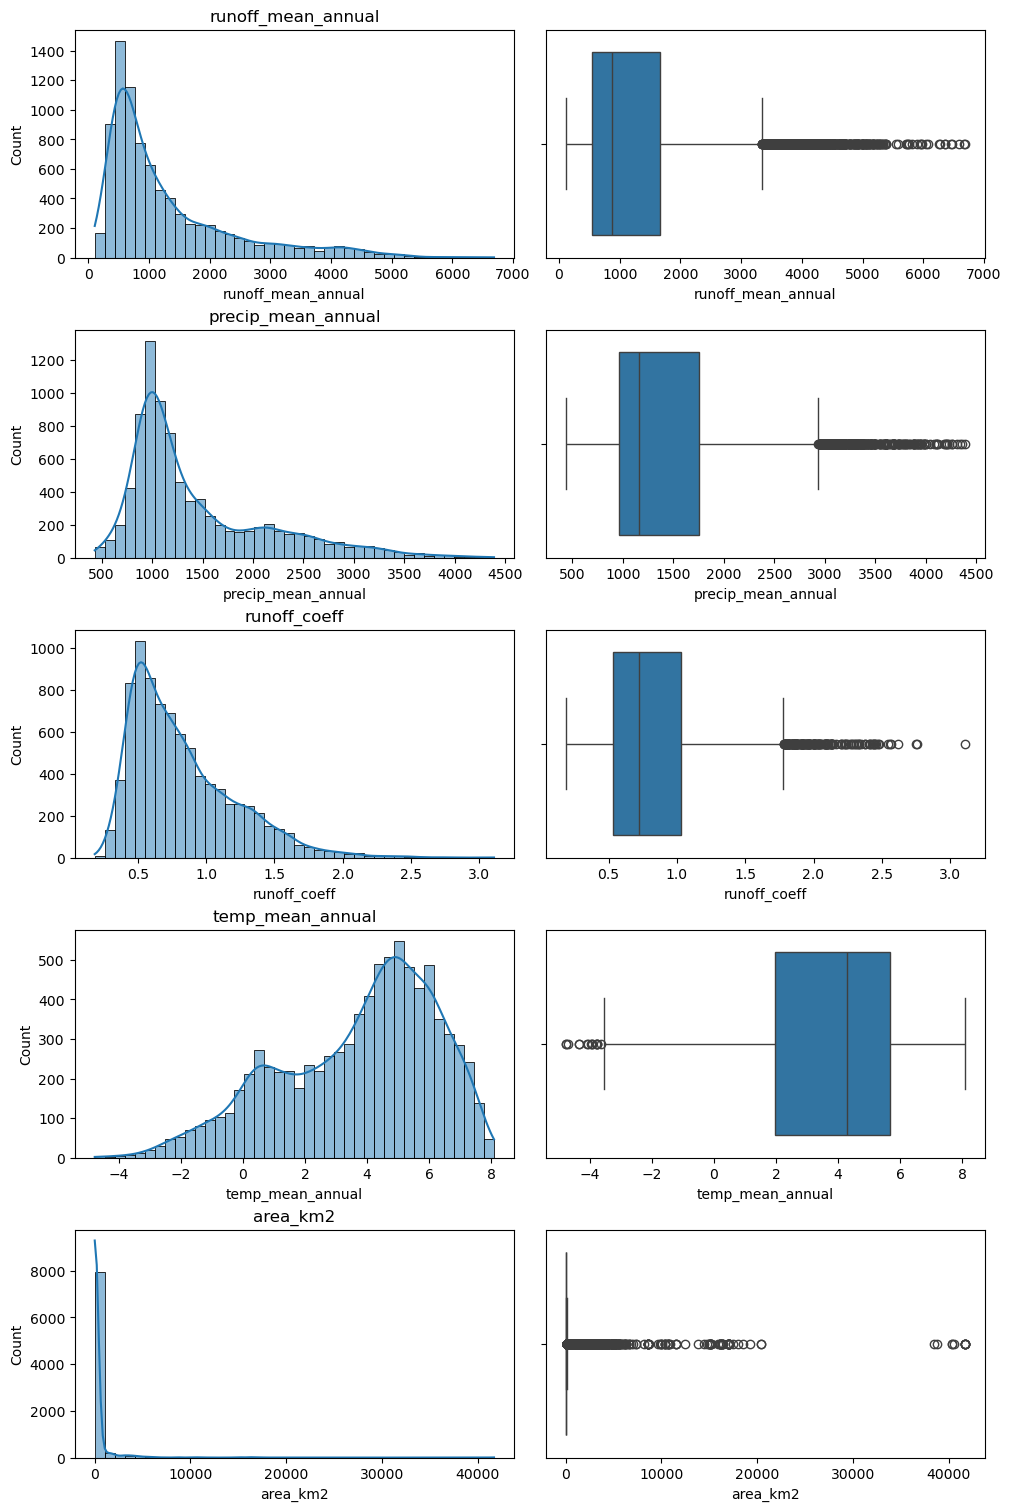

In [41]:
vars_to_plot = ['runoff_mean_annual', 'precip_mean_annual', 'runoff_coeff', 'temp_mean_annual', 'area_km2']

fig, axes = plt.subplots(
    len(vars_to_plot), 2,
    figsize=(10, 3*len(vars_to_plot)),
    constrained_layout=True
)

for i, var in enumerate(vars_to_plot):

    sns.histplot(
        join_df[var],
        bins=40,
        kde=True,
        ax=axes[i, 0]
    )
    axes[i, 0].set_title(var)

    sns.boxplot(
        x=join_df[var],
        ax=axes[i, 1]
    )

plt.show()

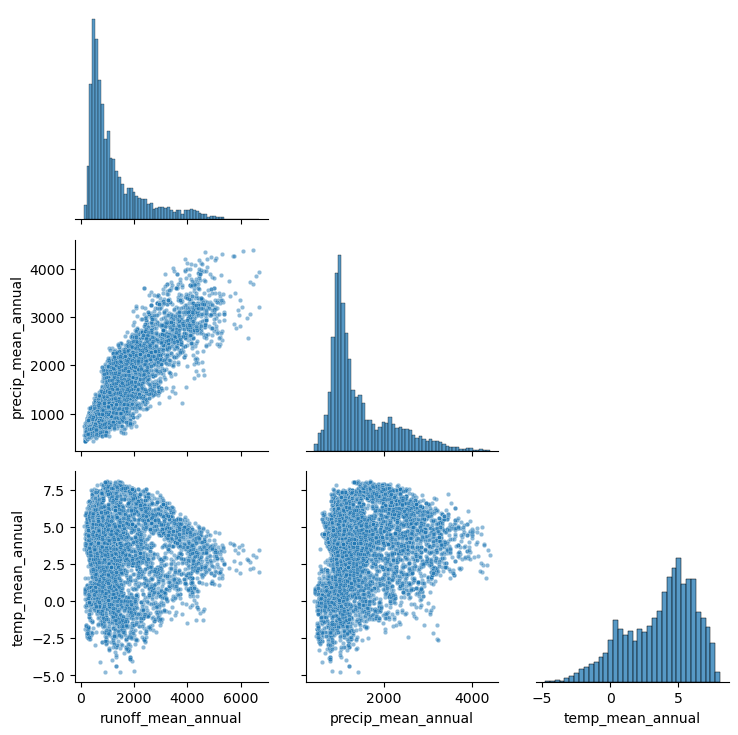

In [62]:
vars_to_plot = [
    "runoff_mean_annual",
    "precip_mean_annual",
    "temp_mean_annual",
]

g = sns.PairGrid(join_df[vars_to_plot], corner=True)

g.map_lower(sns.scatterplot, s=10, alpha=0.5)
g.map_diag(sns.histplot)

def corrfunc(x, y, **kwargs):
    import numpy as np
    ax = plt.gca()
    r = np.corrcoef(x, y)[0, 1]
    ax.annotate(
        f"r = {r:.2f}",
        xy=(0.5, 0.5),
        xycoords="axes fraction",
        ha="center"
    )

g.map_upper(corrfunc)

plt.show()

# Runoff coefficients

* < 0.25 - 0.3: suspicious, not enough runoff given the input.

Values a bit over 1 could be because precipitation inputs are corrected during model calibration. But values substantially over 1 indicate loss of long-term water storage, i.e. through permanent snow pack or glacier ice net melt. i.e. only expect values > 1.5 in catchments that include substantial glacial cover and/or potential for permanent snowfields. i.e. high elevations.
* Values > 1.5: worth investigating
* Values > 2: usually suspicious unless very special circumstances

To do: explore more when have compiled all catch characteristics into one. E.g. look at link with glac area etc.

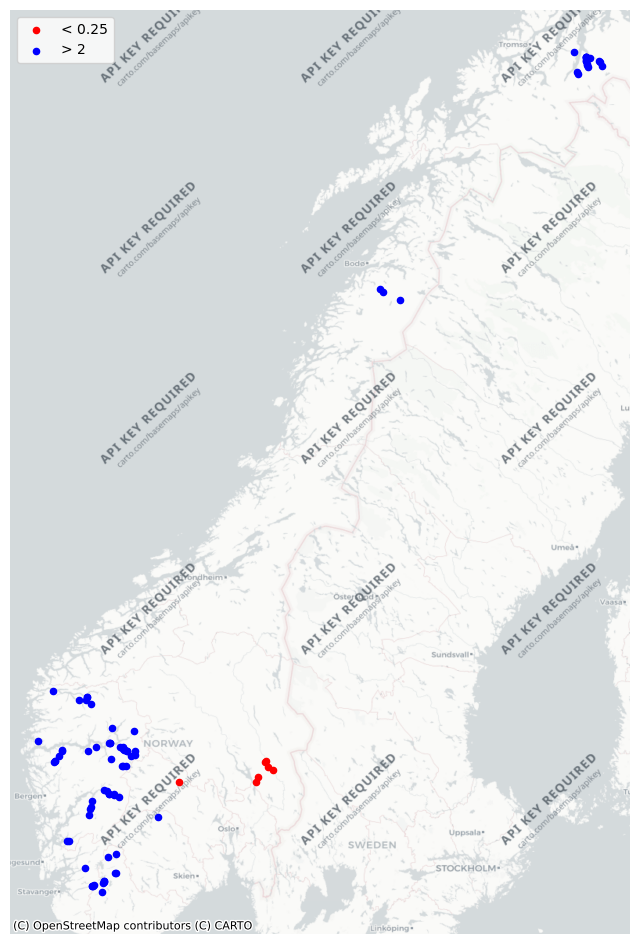

In [59]:
low_thr = 0.25
high_thr = 2

gdf = gpd.GeoDataFrame(
    join_df,
    geometry=gpd.points_from_xy(join_df.lon, join_df.lat),
    crs="EPSG:4326"
).to_crs(3857)

fig, ax = plt.subplots(figsize=(8, 12))

# # background
# ax.scatter(
#     gdf.geometry.x,
#     gdf.geometry.y,
#     c="lightgrey",
#     s=4,
#     alpha=0.3
# )

# low runoff coeff
sel = gdf.runoff_coeff < low_thr
ax.scatter(
    gdf.loc[sel].geometry.x,
    gdf.loc[sel].geometry.y,
    c="red",
    s=20,
    label=f"< {low_thr}"
)

# high runoff coeff
sel = gdf.runoff_coeff > high_thr
ax.scatter(
    gdf.loc[sel].geometry.x,
    gdf.loc[sel].geometry.y,
    c="blue",
    s=20,
    label=f"> {high_thr}"
)

ctx.add_basemap(ax, source=ctx.providers.CartoDB.Positron)

ax.legend()
ax.set_axis_off()
plt.show()